In [12]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#налаштування стилю графіків
sns.set_theme(style="darkgrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

#  Зміст

* [1. Вступ та опис датасету](#section-1)
  * [1.1. Назва, призначення та джерело даних](#section-1-1)
  * [1.2. Опис набору даних](#section-1-2)
* [2. Розвідувальний аналіз даних (EDA)](#section-2)
  * [2.1. Очищення даних та попередня обробка](#section-2-1)
  * [2.2. Статистичний аналіз](#section-2-2)
  * [2.3. Аналіз взаємозв'язків між атрибутами](#section-2-3)

## <a id="section-1"></a>1. Вступ та опис датасету

### <a id="section-1-1"></a>1.1. Назва, призначення та джерело даних

- Назва датасету: Credit Risk Dataset.

- Призначення датасету: набір даних використовується для аналізу фінансового стану клієнтів та оцінки ризиків банківського кредитування.

- Джерело даних: відкрита платформа для аналізу даних та машинного навчання Kaggle.

- Посилання для завантаження:
https://www.kaggle.com/datasets/reyazraiyana/credit-risk-dataset?select=credit+risk+dataset.csv


### <a id="section-1-2"></a>1.2. Опис набору даних

In [10]:
df = pd.read_csv('Data/credit_risk_dataset.csv')
print("=== РОЗМІРНІСТЬ ДАТАСЕТУ ===")
print(f"{df.shape[0]} рядків, {df.shape[1]} стовпчиків\n")

=== РОЗМІРНІСТЬ ДАТАСЕТУ ===
5000 рядків, 12 стовпчиків



In [9]:
# повна таблиця атрибутів
column_info = pd.DataFrame({
    'Назва атрибута': df.columns,
    'Тип даних': df.dtypes.astype(str).values,
    'Кількість заповнених': df.notnull().sum().values,
    'Пропущені значення': df.isnull().sum().values,
    'Унікальні значення': [df[col].nunique() for col in df.columns]
})

display(column_info)

,Назва атрибута,Тип даних,Кількість заповнених,Пропущені значення,Унікальні значення
0,person_age,int64,5000,0,48
1,person_income,int64,5000,0,1167
2,person_home_ownership,str,5000,0,4
3,person_emp_length,float64,4864,136,28
4,loan_intent,str,5000,0,6
5,loan_grade,str,5000,0,7
6,loan_amnt,int64,5000,0,386
7,loan_int_rate,float64,4516,484,272
8,loan_percent_income,float64,5000,0,67
9,cb_person_default_on_file,str,5000,0,2


##### Таблиця 1.1 — Числові атрибути

| Назва атрибута | Тип даних | Опис та значення |
| :--- | :---: | :--- |
| **`person_age`** | `int64` | Вік позичальника (у роках) |
| **`person_income`** | `int64` | Річний дохід позичальника (у грошових одиницях USD) |
| **`person_emp_length`** | `float64` | Офіційний трудовий стаж позичальника (у роках) |
| **`loan_amnt`** | `int64` | Запитувана сума кредиту |
| **`loan_int_rate`** | `float64` | Процентна ставка за кредитом (у відсотках %) |
| **`loan_percent_income`** | `float64` | Відношення суми кредиту до річного доходу (від 0.0 до 1.0) |
| **`cb_person_cred_hist_length`** | `int64` | Тривалість кредитної історії позичальника (у роках) |

---

##### Таблиця 1.2 — Категоріальні атрибути

| Назва атрибута | Тип даних | Категорії | Опис та значення |
| :--- | :---: | :--- | :--- |
| **`person_home_ownership`** | `object` | `RENT`, `MORTGAGE`, `OWN`, `OTHER` | Оренда житла, іпотека, власна нерухомість, інше |
| **`loan_intent`** | `object` | `PERSONAL`, `EDUCATION`, `MEDICAL`, `VENTURE`, `HOMEIMPROVEMENT`, `DEBTCONSOLIDATION` | Особисті потреби, навчання, медицина, бізнес/стартап, ремонт, консолідація боргів |
| **`loan_grade`** | `object` | `A`, `B`, `C`, `D`, `E`, `F`, `G` | Клас ризику за шкалою банку: A — найменший ризик, G — найвищий |
| **`cb_person_default_on_file`** | `object` | `Y`, `N` | `Y` — є дані про минулі дефолти;<br>`N` — чиста історія |

---

##### Таблиця 1.3 — Цільовий атрибут

| Назва атрибута | Тип даних | Значення мітки | Опис та значення |
| :--- | :---: | :---: | :--- |
| **`loan_status`** | `int64` | `0`, `1` | **`0`** — надійний позичальник (кредит виплачено);<br>**`1`** — ризиковий позичальник (дефолт) |

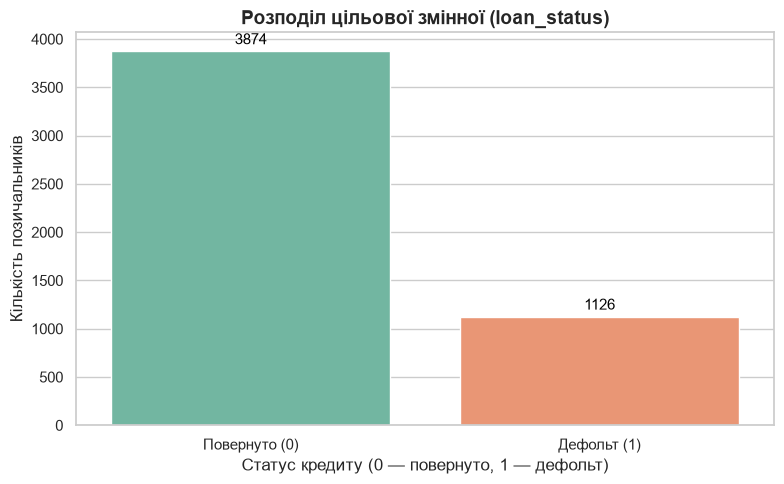

In [8]:
#візуалізація розподілу loan_status
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df,
    x='loan_status',
    hue='loan_status',
    palette='Set2',
    legend=False
)

plt.title('Розподіл цільової змінної (loan_status)', fontsize=14, fontweight='bold')
plt.xlabel('Статус кредиту (0 — повернуто, 1 — дефолт)', fontsize=12)
plt.ylabel('Кількість позичальників', fontsize=12)
plt.xticks([0, 1], ['Повернуто (0)', 'Дефольт (1)'])

#додаємо цифри над стовпчиками
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='baseline',
        fontsize=11, color='black',
        xytext=(0, 5), textcoords='offset points'
    )

plt.tight_layout()
plt.show()

## <a id="section-2"></a>2. Розвідувальний аналіз даних (EDA)

### <a id="section-2-1"></a>2.1. Очищення даних та попередня обробка

#### 1. Аналіз та обрбка пропущених значень (Missing Values)

Під час виведення інформації про атрибути датасету були пропуски у двох числових атрибутах:

| Назва атрибута | Кількість пропусків | Відсоток пропусків (%) |
| :--- | :---: | :---: |
| **`person_emp_length`** (Трудовий стаж) | 136 | 2.72% |
| **`loan_int_rate`** (Відсоткова ставка) | 484 | 9.68% |


У банківській сфері та фінансовому аналізі штучне заповнення даних (наприклад, заповнення медіаною чи середнім значенням) без підтвердженої методології може призвести до викривлення первинного розподілу та спотворення даних

З огляду на це прийнято:
1. Пропущені значення (`NaN`) у стовпцях `person_emp_length` та `loan_int_rate` залишаються без змін
2. **Створення індикаторів відсутності даних:** для кожного з цих стовпчиків формуються додаткові бінарні прапорці (`person_emp_length_is_missing` та `loan_int_rate_is_missing`). Вони фіксують сам факт відсутності інформації (`1` - дані відсутні, `0` - дані присутні)


In [15]:
df['person_emp_length_is_missing'] = df['person_emp_length'].isnull().astype(int)
df['loan_int_rate_is_missing'] = df['loan_int_rate'].isnull().astype(int)

#### 2. Пошук та видалення аномалій і дублікатів

In [20]:
# 1. ДУБЛІКАТИ
#знаходимо всі рядки, які мають хоча б один повний дублікат
#(keep=False показує і оригінал, і його копію)
duplicates_df = df[df.duplicated(keep=False)].sort_values(by=['person_age', 'person_income', 'loan_amnt'])

print(f"=== ЗНАЙДЕНО ДУБЛЬОВАНИХ РЯДКІВ: {len(duplicates_df)} ===")

if len(duplicates_df) > 0:
    print("Приклади:")
    display(duplicates_df.head(10))
else:
    print("немає")

=== ЗНАЙДЕНО ДУБЛЬОВАНИХ РЯДКІВ: 10 ===
Приклади:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,person_emp_length_is_missing,loan_int_rate_is_missing
3732,21,27600,RENT,4.0,EDUCATION,A,7500,6.76,0.27,N,4,0,0,0
3947,21,27600,RENT,4.0,EDUCATION,A,7500,6.76,0.27,N,4,0,0,0
2328,23,90000,MORTGAGE,1.0,EDUCATION,B,12000,12.18,0.13,N,4,0,0,0
4179,23,90000,MORTGAGE,1.0,EDUCATION,B,12000,12.18,0.13,N,4,0,0,0
3716,24,33321,OWN,4.0,VENTURE,C,12250,13.11,0.37,Y,4,0,0,0
3894,24,33321,OWN,4.0,VENTURE,C,12250,13.11,0.37,Y,4,0,0,0
1269,27,100000,MORTGAGE,11.0,PERSONAL,A,14400,NaN,0.14,N,8,0,0,1
3767,27,100000,MORTGAGE,11.0,PERSONAL,A,14400,NaN,0.14,N,8,0,0,1
354,28,33600,MORTGAGE,12.0,MEDICAL,A,3000,5.42,0.09,N,5,0,0,0
402,28,33600,MORTGAGE,12.0,MEDICAL,A,3000,5.42,0.09,N,5,0,0,0


Перевірку на дублікати було здійснено, щоб побачити загальну картину унікальності даних, і як бачимо кількість дублікатів мала.
В цьому випадку не будемо їх видаляти, оскільки в нас немає конкретної інформації, яка б свідчила що це помилкові дублікати (наприклад при вивантаженні бази даних). Тут дійсно може бути, що два різних позичальники мають однаковий вік, дохід та інше, оскільки атрибути є досить загальними

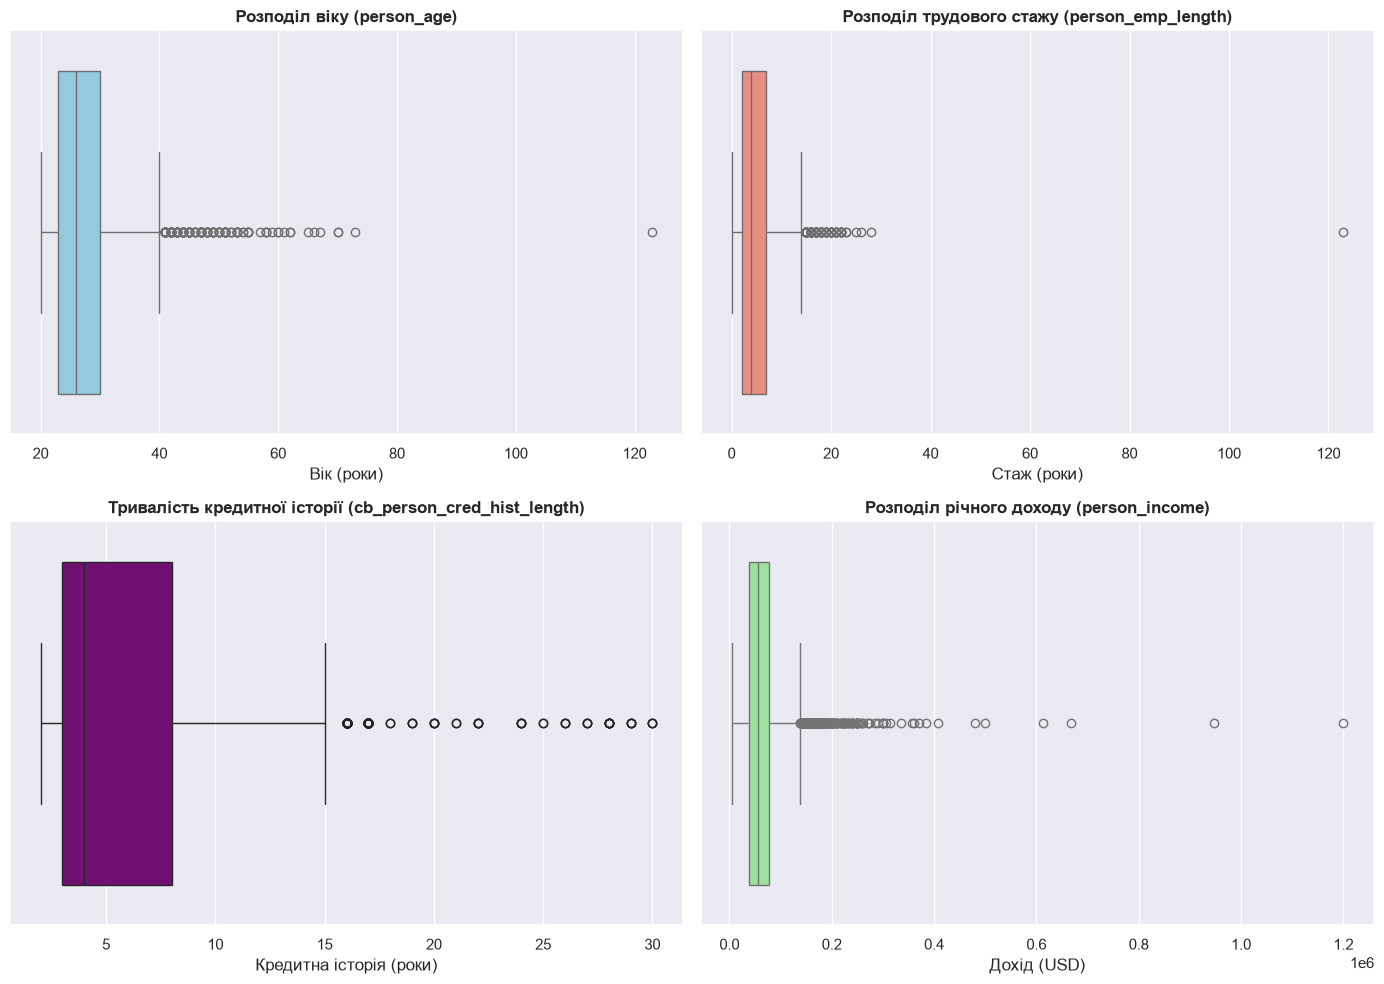

In [24]:
# 2. ВІЗУАЛІЗАЦІЯ ВИКИДІВ
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Графік 1: вік
sns.boxplot(ax=axes[0, 0], x=df['person_age'], color='skyblue')
axes[0, 0].set_title('Розподіл віку (person_age)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Вік (роки)')

# Графік 2: стаж
sns.boxplot(ax=axes[0, 1], x=df['person_emp_length'], color='salmon')
axes[0, 1].set_title('Розподіл трудового стажу (person_emp_length)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Стаж (роки)')

# Графік 3: тривалість кредитної історії (cb_person_cred_hist_length)
sns.boxplot(ax=axes[1, 0], x=df['cb_person_cred_hist_length'], color='purple')
axes[1, 0].set_title('Тривалість кредитної історії (cb_person_cred_hist_length)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Кредитна історія (роки)')

# Графік 4: річний дохід
sns.boxplot(ax=axes[1, 1], x=df['person_income'], color='lightgreen')
axes[1, 1].set_title('Розподіл річного доходу (person_income)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Дохід (USD)')

plt.tight_layout()
plt.show()

Бачимо присутні викиди:

- **Вік (person_age)** та **Стаж (person_emp_length)**: тут присутні явні помилки введення даних, бо такі значення не можливі, прибераєм

- **Тривалість кредитної історії (cb_person_cred_hist_length)** та **Дохід (person_income)**: тут вже викиди нормальні, у випадку з доходом це можливо

In [25]:
#залишаємо лише фізично можливі значення
df = df[(df['person_age'] <= 100) & (df['person_emp_length'].isna() | (df['person_emp_length'] <= 90))].copy()

#### 3. Кодування категоріальних змінних (Categorical Encoding)

Для підготовки категоріальних текстових ознак до використання в алгоритмах кластеризації два підходи залежно від природи даних:

1. **Ordinal Encoding (Порядкове кодування):**
   * **`loan_grade`**: Має чітку ієрархію ризику ($A \rightarrow 0, B \rightarrow 1, \dots, G \rightarrow 6$).
   * **`cb_person_default_on_file`**: Перетворено у бінарний прапорець ($N \rightarrow 0, Y \rightarrow 1$).

2. **One-Hot Encoding (OHE):**
   * **`person_home_ownership`** та **`loan_intent`**: Не мають внутрішнього порядку, тому перетворені на окремі бінарні стовпці ($0$ або $1$) за допомогою `pd.get_dummies()`.

In [26]:
# =========================================================
# КОДУВАННЯ КАТЕГОРІАЛЬНИХ ЗМІННИХ
# =========================================================

#створюємо копію датасету для кодування
df_encoded = df.copy()

# 1. ORDINAL ENCODING

# мапінг (A -> 0 ... G -> 6)
grade_mapping = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6}
df_encoded['loan_grade'] = df_encoded['loan_grade'].map(grade_mapping)

# мапінг для дефолту в історії (N -> 0, Y -> 1)
default_mapping = {'N': 0, 'Y': 1}
df_encoded['cb_person_default_on_file'] = df_encoded['cb_person_default_on_file'].map(default_mapping)

# 2. ONE-HOT ENCODING (Для номінальних категорій)

df_encoded = pd.get_dummies(
    df_encoded,
    columns=['person_home_ownership', 'loan_intent'],
    dtype=int
)

#  результати кодування
print("=== РОЗМІРНІСТЬ ДАТАСЕТУ ПІСЛЯ КОДУВАННЯ ===")
print(f"Початкова кількість стовпчиків: {df.shape[1]}")
print(f"Нова кількість стовпчиків: {df_encoded.shape[1]}\n")

print("=== ПРИКЛАД КОДОВАНИХ ДАНИХ ===")
display(df_encoded.head())

=== РОЗМІРНІСТЬ ДАТАСЕТУ ПІСЛЯ КОДУВАННЯ ===
Початкова кількість стовпчиків: 14
Нова кількість стовпчиків: 22

=== ПРИКЛАД КОДОВАНИХ ДАНИХ ===


,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,person_emp_length_is_missing,loan_int_rate_is_missing,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,24,28000,6.0,1,10000,10.37,0.36,0,2,0,0,0,0,0,1,0,0,0,1,0,0,0
1,27,64000,0.0,2,10000,15.27,0.16,1,10,0,0,0,0,0,0,1,0,0,0,0,1,0
2,26,72000,10.0,3,16000,NaN,0.22,0,3,0,0,1,1,0,0,0,0,1,0,0,0,0
3,23,27996,7.0,0,10000,NaN,0.36,0,2,1,0,1,0,0,0,1,1,0,0,0,0,0
4,30,44500,2.0,4,13000,16.32,0.29,0,6,1,0,0,0,0,0,1,0,0,0,1,0,0


### <a id="section-2-2"></a>2.2. Статистичний аналіз